*Mathematical Foundations of Robotics · Chapter 6 — Manipulator Dynamics*

# 6.1 Mass Distribution and the Inertia Tensor

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/06-manipulator-dynamics/6.1-mass-distribution-and-the-inertia-tensor.ipynb)

A manipulator accelerates only if forces and torques are applied, and *how much* torque is needed depends on how the
mass of every link is distributed in space. For translation all that matters is the total mass and the position
of the centre of mass. For rotation the answer is richer: the resistance of a body to angular acceleration depends on
the axis, and a single number is not enough. This notebook develops the **inertia tensor** — the $3\times3$ symmetric matrix
that plays for rotation the role that mass plays for translation — together with the tools needed to use it:
the parallel-axis theorem, the rotation of a tensor from one frame to another, principal axes, and tests of physical
validity. Every formula is checked against the inertial data that MuJoCo reads from real robot models.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 6, §6.3 (mass distribution) |
| **Parallel reading** | Lynch & Park Ch. 8 (§8.2, dynamics of a single rigid body) · Spong et al., the chapter on dynamics · Siciliano et al. Ch. 7 · Corke *RVC* Ch. 9 |
| **Lectures** | [Prof. G. C. Nandi, *Mathematical Foundation of Robotics*, playlist 1, lessons 26–29 (dynamics)](https://youtube.com/playlist?list=PLFWlHcAOSQboRkC6DtxKIqXmErq0oc7S3) · [Northwestern *Modern Robotics*, all videos](https://www.youtube.com/playlist?list=PLggLP4f-rq02vX0OQQ5vrCxbJrzamYDfx) (Chapter 8, dynamics of open chains) · [Sapienza *Robotics 2*, Prof. A. De Luca](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm) |
| **Prerequisites** | [2.1 Positions, Orientations and Frames](../02-spatial-descriptions-and-transformations/2.1-positions-orientations-and-frames.ipynb) · [2.3 Homogeneous Transformations](../02-spatial-descriptions-and-transformations/2.3-homogeneous-transformations.ipynb) · eigenvalues of a symmetric matrix |
| **Study time** | about 2.5 hours |

## Learning objectives

After working through this notebook you should be able to:

1. **Define** the centre of mass, the inertia tensor, the moments and the products of inertia of a rigid body, and **compute** them for a set of point masses.
2. **Derive** the tensor of a rod, a box and a cylinder by integration, and **use** the standard formulas for a sphere, an ellipsoid and a capsule.
3. **Apply** the parallel-axis theorem (and its inverse) and **assemble** the tensor of a composite body from its parts.
4. **Rotate** an inertia tensor into another frame, **find** its principal moments and principal axes, and **interpret** them geometrically (the inertia ellipsoid).
5. **Test** whether a given matrix can be the inertia tensor of a real body (positive definiteness and the triangle inequality).
6. **Read** the mass, centre of mass and inertia of the links of a real robot from a MuJoCo model, relate them to the diagonal of the joint-space mass matrix, and **verify** your hand calculations against the simulator.

## Contents

1. [Why the distribution of mass matters](#1.-Why-the-distribution-of-mass-matters)
2. [The centre of mass and the first moment](#2.-The-centre-of-mass-and-the-first-moment)
3. [The inertia tensor](#3.-The-inertia-tensor)
4. [Frames, rotation of a tensor and principal axes](#4.-Frames,-rotation-of-a-tensor-and-principal-axes)
5. [Tensors of simple solids](#5.-Tensors-of-simple-solids)
6. [The parallel-axis theorem and composite bodies](#6.-The-parallel-axis-theorem-and-composite-bodies)
7. [Which matrices can be inertia tensors?](#7.-Which-matrices-can-be-inertia-tensors?)
8. [Inertia of real robots in MuJoCo](#8.-Inertia-of-real-robots-in-MuJoCo)
9. [Worked examples](#9.-Worked-examples)
10. [Summary, common mistakes and exercises](#10.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import dynamics as dyn
from rgkit import transforms as tf
from rgkit.transforms import rotx, roty, rotz, rot_axis_angle, skew

## 1. Why the distribution of mass matters

Newton's second law for a particle, $\mathbf F = m\,\mathbf a$, contains one scalar of the body, its mass. For an
extended rigid body the law splits in two. The **translation** of the centre of mass obeys $\mathbf F = m\,\mathbf a_C$
exactly as for a particle. The **rotation** about the centre of mass obeys Euler's law, which relates the applied torque
to the rate of change of the angular momentum $\mathbf L$ (the next notebook derives it). The angular momentum is
linear in the angular velocity,

$$
\mathbf L = I\,\boldsymbol\omega ,
$$

but the proportionality factor $I$ is **not** a scalar: it is a $3\times3$ matrix, because a body is generally harder to
spin about one axis than about another, and because spinning it about one axis can produce angular momentum along
a different one. A long thin rod about its own axis is easy to spin and about a transverse axis is much harder.
The matrix $I$ is the *inertia tensor*; it is a property of the body (together with the choice of reference point and
axes) and it is the only place in the equations of motion where the **shape** of the link enters.

A manipulator makes this concrete. When joint 2 of an arm accelerates, the whole forearm swings as a rigid body about
that joint, and the torque required is governed by the forearm's inertia **about the joint axis** — a quantity that
combines the tensor of the link with the distance of its centre of mass from the axis. The notebook builds up to
exactly this calculation, and ends by performing it for a real UR5e.

## 2. The centre of mass and the first moment

For a body made of point masses $m_k$ at positions $\mathbf r_k$, or of a continuum with mass density $\rho$,

$$
m = \sum_k m_k = \int \rho\,dV,\qquad
\mathbf h = \sum_k m_k\mathbf r_k = \int \mathbf r\,\rho\,dV,\qquad
\mathbf r_C = \frac{\mathbf h}{m}.
$$

The vector $\mathbf h = m\,\mathbf r_C$ is the **first moment of mass** about the origin of the frame in which the
$\mathbf r_k$ are written. It is the quantity that determines the *gravity torque* of a link (gravity acts as a force
$m\mathbf g$ through $\mathbf r_C$) and the way in which the link's mass enters the
Newton–Euler recursion of Notebook 6.2. Choosing the origin of a frame at the centre of mass makes $\mathbf h=\mathbf 0$ and removes
many terms; this is why Craig expresses link inertias about the centre of mass.

In [2]:
# A "link" modelled by four point masses (kg) at positions (m) in the link frame
masses = np.array([1.0, 2.0, 1.5, 0.5])
points = np.array([[0.0, 0.0, 0.0], [0.3, 0.0, 0.0], [0.6, 0.05, 0.0], [0.6, -0.05, 0.02]])
m_tot = masses.sum()
h = masses @ points                      # first moment  sum m_k r_k
r_C = h / m_tot                          # centre of mass
print(f"total mass m = {m_tot:.3f} kg,  centre of mass r_C = {r_C.round(4)} m")
print("first moment about the centre of mass (must vanish):", (masses @ (points - r_C)).round(12) + 0.0)

total mass m = 5.000 kg,  centre of mass r_C = [0.36  0.01  0.002] m
first moment about the centre of mass (must vanish): [0. 0. 0.]


## 3. The inertia tensor

Let the body rotate with angular velocity $\boldsymbol\omega$ about a **fixed point** $O$ (or about its centre of mass), and let $\mathbf r$ be
the position of a mass element relative to that point. The velocity of the element is $\mathbf v=\boldsymbol\omega\times\mathbf r$, so the angular
momentum about $O$ is

$$
\mathbf L=\int \mathbf r\times\mathbf v\,dm=\int \mathbf r\times(\boldsymbol\omega\times\mathbf r)\,dm
=\int\big[(\mathbf r\cdot\mathbf r)\,\boldsymbol\omega-(\mathbf r\cdot\boldsymbol\omega)\,\mathbf r\big]\,dm
=\underbrace{\int\big[(\mathbf r^{\mathsf T}\mathbf r)\,E-\mathbf r\mathbf r^{\mathsf T}\big]\,dm}_{I}\;\boldsymbol\omega .
$$

The step uses the identity $\mathbf a\times(\mathbf b\times\mathbf c)=(\mathbf a\cdot\mathbf c)\mathbf b-(\mathbf a\cdot\mathbf b)\mathbf c$, and $E$ is the
identity matrix. Writing $\mathbf r=(x,y,z)$ gives the explicit form

> **Definition (inertia tensor).**
> $$
> {}^{A}I=\begin{bmatrix} I_{xx} & -I_{xy} & -I_{xz}\\ -I_{xy} & I_{yy} & -I_{yz}\\ -I_{xz} & -I_{yz} & I_{zz}\end{bmatrix},
> \qquad
> \begin{aligned}
> I_{xx}&=\textstyle\int (y^2+z^2)\,dm, & I_{xy}&=\textstyle\int xy\,dm,\\
> I_{yy}&=\textstyle\int (x^2+z^2)\,dm, & I_{xz}&=\textstyle\int xz\,dm,\\
> I_{zz}&=\textstyle\int (x^2+y^2)\,dm, & I_{yz}&=\textstyle\int yz\,dm.
> \end{aligned}
> $$

The three diagonal entries are the **moments of inertia** about the axes: $I_{xx}$ is the sum of mass times the *squared distance from the $x$ axis*.
The three independent off-diagonal entries are the **products of inertia**; Craig's convention, followed here, defines them as
$+\int xy\,dm$ etc. and places them in the tensor with a minus sign. (Some authors put the products in the tensor with a plus sign — always check.)
The leading superscript $A$ records that the **components** are written in the axes of frame $\{A\}$ and that the origin is the chosen reference point.

Two consequences are used constantly:

$$
\mathbf L=I\,\boldsymbol\omega,\qquad K_{\text{rot}}=\tfrac12\,\boldsymbol\omega^{\mathsf T} I\,\boldsymbol\omega .
$$

Note that $\mathbf L$ is **not** parallel to $\boldsymbol\omega$ in general; they are parallel only when $\boldsymbol\omega$ lies along a *principal axis* (Section 4).

In [3]:
def inertia_of_points(masses, points, about=(0, 0, 0)):
    """I = sum m_k (r.r E - r r^T) with r measured from the point `about` (this is the definition, written out)."""
    I = np.zeros((3, 3))
    for m_k, p in zip(masses, np.asarray(points) - np.asarray(about)):
        I += m_k * (p @ p * np.eye(3) - np.outer(p, p))
    return I

I_C = inertia_of_points(masses, points, about=r_C)              # about the centre of mass
display(Math(matrix_to_latex(I_C, 5, r"{}^{C}I\ (\mathrm{kg\,m^2})")))
print("library agrees:", np.allclose(I_C, dyn.inertia_point_masses(masses, points, about=r_C)))

# L = I w by brute force: sum of r x (w x r) m, and the kinetic energy 1/2 sum m |w x r|^2
w = np.array([1.0, -2.0, 0.5])                                  # rad/s
rel = points - r_C
L_direct = sum(m_k * np.cross(r, np.cross(w, r)) for m_k, r in zip(masses, rel))
K_direct = 0.5 * sum(m_k * np.linalg.norm(np.cross(w, r)) ** 2 for m_k, r in zip(masses, rel))
print("L = I w            :", np.allclose(L_direct, I_C @ w), " L =", (I_C @ w).round(4))
print("K = 1/2 w^T I w    :", np.isclose(K_direct, 0.5 * w @ I_C @ w), f" K = {K_direct:.5f} J")
print("L parallel to w?    ", np.allclose(np.cross(L_direct, w), 0), " (in general it is not)")

<IPython.core.display.Math object>

library agrees: True
L = I w            : True  L = [ 0.0275 -0.5161  0.1246]
K = 1/2 w^T I w    : True  K = 0.56096 J
L parallel to w?     False  (in general it is not)


## 4. Frames, rotation of a tensor and principal axes

**The tensor depends on the axes.** If the same body is described in frame $\{B\}$ and in a frame $\{A\}$ with the same origin and
$\{B\}$ rotated relative to it by ${}^{A}_{B}R$, then $\boldsymbol\omega$ and $\mathbf L$ transform as vectors:
${}^{A}\boldsymbol\omega={}^{A}_{B}R\,{}^{B}\boldsymbol\omega$ and ${}^{A}\mathbf L={}^{A}_{B}R\,{}^{B}\mathbf L$. Since
${}^{B}\mathbf L={}^{B}I\,{}^{B}\boldsymbol\omega$,

$$
{}^{A}I={}^{A}_{B}R\;{}^{B}I\;{}^{A}_{B}R^{\mathsf T}.
$$

The diagonal moments change with the axes, the trace $I_{xx}+I_{yy}+I_{zz}=2\int|\mathbf r|^2dm$ does not, and **products of inertia appear
as soon as the axes are not aligned with the symmetry of the body.**

**Principal axes.** Because $I$ is real and symmetric, the spectral theorem gives an orthogonal matrix $V$ and real numbers
$I_1\le I_2\le I_3$ with $I=V\,\mathrm{diag}(I_1,I_2,I_3)\,V^{\mathsf T}$. The columns of $V$ are the **principal axes** and $I_k$ the
**principal moments**. In the frame spanned by the principal axes the products of inertia vanish. Spinning the body about
a principal axis gives $\mathbf L=I_k\boldsymbol\omega\parallel\boldsymbol\omega$: no gyroscopic torque is needed to keep the axis fixed
(a *balanced* rotor). A body with a symmetry axis has two equal principal moments; a sphere has three.

**The inertia ellipsoid.** The set of vectors $\boldsymbol\omega$ with $\tfrac12\boldsymbol\omega^{\mathsf T}I\boldsymbol\omega=\text{const}$ is an ellipsoid whose
semi-axes lie along the principal axes and have lengths proportional to $1/\sqrt{I_k}$: it is *long* in the directions that are
*easy* to spin. The figure draws it for an L-shaped bracket made of two bars, together with its principal axes at the centre of mass.
(MuJoCo draws instead the *equivalent box*: the uniform cuboid with the same mass and the same principal moments; see Section 5.)

mass 3.5 kg, centre of mass [0.1357 0.1357 0.05  ] m


<IPython.core.display.Math object>

principal moments: [0.0244 0.0758 0.0944]  principal axes (columns):
 [[-0.7071  0.7071  0.    ]
 [ 0.7071  0.7071  0.    ]
 [ 0.      0.     -1.    ]]


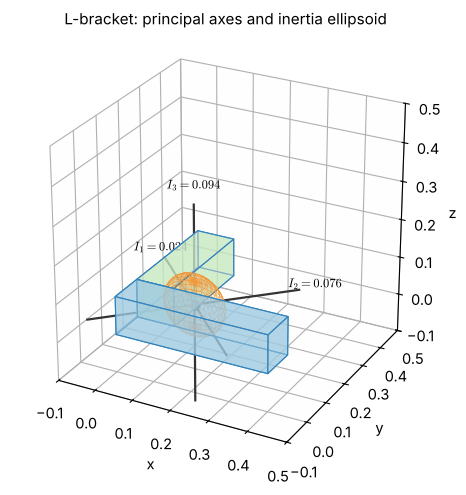

In [4]:
# An L-shaped bracket: bar A along x, bar B along y; both 0.1 m thick
parts = [(2.0, np.array([0.20, 0.05, 0.05]), dyn.inertia_box(2.0, 0.4, 0.1, 0.1)),     # (mass, centre, I about own centre)
         (1.5, np.array([0.05, 0.25, 0.05]), dyn.inertia_box(1.5, 0.1, 0.3, 0.1))]
m_L, com_L, I_L = dyn.combine_bodies(parts)                     # composite body about its centre of mass (Section 6)
lam, V = dyn.principal_axes(I_L)
print(f"mass {m_L} kg, centre of mass {com_L.round(4)} m")
display(Math(matrix_to_latex(I_L, 4, r"{}^{C}I\ \mathrm{(kg\,m^2)}")))
print("principal moments:", lam.round(5), " principal axes (columns):\n", V.round(4) + 0.0)

fig = plt.figure(figsize=(6.6, 5.6)); ax = new_axes3d(fig.add_subplot(111, projection="3d"), lim=[(-0.1, 0.5), (-0.1, 0.5), (-0.1, 0.5)], elev=26, azim=-62)
draw_box(ax, tf.make_T(np.eye(3), parts[0][1]), (0.4, 0.1, 0.1), color="#9ecae1")
draw_box(ax, tf.make_T(np.eye(3), parts[1][1]), (0.1, 0.3, 0.1), color="#c7e9c0")
draw_point(ax, com_L, color="k", size=40)
scale = 0.12 / (1 / np.sqrt(lam)).max()                          # semi-axes proportional to 1/sqrt(I_k)
u, v = np.linspace(0, 2 * np.pi, 36), np.linspace(0, np.pi, 18)
sph = np.stack([np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v))])
ell = np.einsum("ij,jkl->ikl", V @ np.diag(scale / np.sqrt(lam)), sph) + com_L[:, None, None]
ax.plot_wireframe(*ell, color="#ff7f0e", alpha=0.45, lw=0.6)
for k in range(3):
    d = V[:, k] * np.sign(V[2, k] if abs(V[2, k]) > 0.5 else V[1, k])          # draw each axis with a sensible sign
    ax.plot(*np.c_[com_L - 0.26 * d, com_L + 0.26 * d], color="#333", lw=1.6)
    ax.text(*(com_L + 0.30 * d), rf"$I_{k + 1}={lam[k]:.3f}$", fontsize=9, ha="center")
ax.set_title("L-bracket: principal axes and inertia ellipsoid", fontsize=11)
plt.show()

The long axis of the ellipsoid points along the principal axis with the **smallest** principal moment ($I_1$, the direction in which the mass hugs the axis), and the
shortest one along the largest moment. For a flat bracket lying in the $xy$ plane the axis perpendicular to the plane ($z$) is always principal, and its moment
is the largest, $I_3=I_1+I_2$ (the *perpendicular-axis theorem* for a thin plate; for our thick bars it holds only approximately).

The next cell uses the rotation law to check that a tensor really is the same physical object in rotated axes: the **principal moments do not change** and
the kinetic energy of a given physical motion is the same in either description.

In [5]:
R = rot_axis_angle([1, 2, 3], 0.9)                         # an arbitrary rotation of the axes
I_rot = R @ I_L @ R.T
w_A = np.array([0.3, -1.1, 0.8])                           # an angular velocity written in the original axes
w_B = R @ w_A                                              # the same physical vector in the rotated axes
print("principal moments unchanged :", np.allclose(np.linalg.eigvalsh(I_rot), np.linalg.eigvalsh(I_L)))
print("trace unchanged             :", np.isclose(np.trace(I_rot), np.trace(I_L)))
print("kinetic energy unchanged    :", np.isclose(0.5 * w_A @ I_L @ w_A, 0.5 * w_B @ I_rot @ w_B))
print("products of inertia appear  :", I_rot.round(4)[np.triu_indices(3, 1)])

principal moments unchanged : True
trace unchanged             : True
kinetic energy unchanged    : True
products of inertia appear  : [ 0.0011  0.0303 -0.0016]


### Interactive explorer: a box rotated about $\hat Z$

The explorer rotates a rectangular body about $\hat Z$ and plots the entries of its tensor in the fixed axes. The diagonal entries oscillate between the principal moments, the product $I_{xy}$ appears whenever the principal axes are not aligned with $x$ and $y$, and the quantity
$I_{xx}+I_{yy}$ (the moment about $z$ is untouched) stays constant.

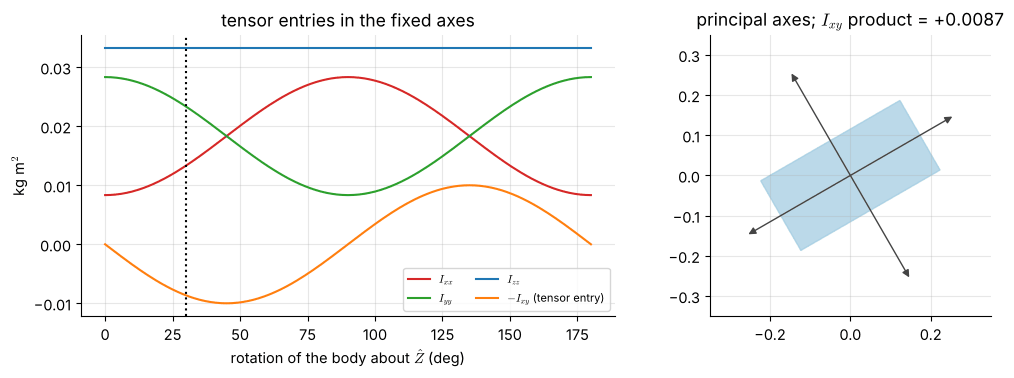

In [6]:
def explorer(angle_deg=30, a=0.40, b=0.20, c=0.10):
    I0 = dyn.inertia_box(2.0, a, b, c)
    ang = np.linspace(0, 180, 181)
    comps = np.array([dyn.rotate_inertia(I0, rotz(deg(t))) for t in ang])
    Ir = dyn.rotate_inertia(I0, rotz(deg(angle_deg)))
    fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw=dict(width_ratios=[1.5, 1]))
    ax = axs[0]
    for (i, j), lab, col in [((0, 0), r"$I_{xx}$", "#d62728"), ((1, 1), r"$I_{yy}$", "#2ca02c"), ((2, 2), r"$I_{zz}$", "#1f77b4"), ((0, 1), r"$-I_{xy}$ (tensor entry)", "#ff7f0e")]:
        ax.plot(ang, comps[:, i, j], color=col, label=lab)
    ax.axvline(angle_deg, color="k", ls=":"); ax.set_xlabel(r"rotation of the body about $\hat Z$ (deg)"); ax.set_ylabel(r"kg m$^2$")
    ax.legend(fontsize=8, ncol=2); ax.set_title("tensor entries in the fixed axes")
    ax = axs[1]
    rect = np.array([[-a, -b], [a, -b], [a, b], [-a, b], [-a, -b]]).T / 2
    Rz = rotz(deg(angle_deg))[:2, :2]
    ax.fill(*(Rz @ rect), color="#9ecae1", alpha=0.7)
    lam_, V_ = dyn.principal_axes(Ir)
    for k in range(2):
        d = V_[:2, k] * 0.3
        ax.annotate("", xy=d, xytext=-d, arrowprops=dict(arrowstyle="<|-|>", color="#444"))
    ax.set_xlim(-0.35, 0.35); ax.set_ylim(-0.35, 0.35); ax.set_aspect("equal")
    ax.set_title(f"principal axes; $I_{{xy}}$ product = {-Ir[0, 1]:+.4f}")
    plt.tight_layout(); plt.show()

interact(explorer, angle_deg=widgets.IntSlider(30, 0, 180, 5), a=widgets.FloatSlider(0.40, min=0.1, max=0.6, step=0.05),
         b=widgets.FloatSlider(0.20, min=0.1, max=0.6, step=0.05), c=widgets.FloatSlider(0.10, min=0.05, max=0.3, step=0.05))

## 5. Tensors of simple solids

For solids of uniform density the integrals of Section 3 can be evaluated in closed form. We derive the two cases that are
used most often, a rectangular box and a circular cylinder, with a computer-algebra system, so that every step is
visible; the other entries of the table follow in the same way.

In [7]:
import sympy as sp
x, y, z, rho = sp.symbols("x y z rho", positive=True)
a, b, c, m, r, hh = sp.symbols("a b c m r h", positive=True)

# Box with full side lengths a, b, c, centred at the origin: rho = m/(abc)
dens = m / (a * b * c)
Ixx = sp.integrate(dens * (y**2 + z**2), (x, -a / 2, a / 2), (y, -b / 2, b / 2), (z, -c / 2, c / 2))
print("box      I_xx =", sp.simplify(Ixx))

# Cylinder (axis z, radius r, height h) in cylindrical coordinates (rho_c, phi, z): dV = rho_c drho_c dphi dz
rc, phi = sp.symbols("rho_c phi", positive=True)
dens = m / (sp.pi * r**2 * hh)
Izz = sp.integrate(dens * rc**2 * rc, (rc, 0, r), (phi, 0, 2 * sp.pi), (z, -hh / 2, hh / 2))
Ixx_c = sp.integrate(dens * ((rc * sp.sin(phi))**2 + z**2) * rc, (rc, 0, r), (phi, 0, 2 * sp.pi), (z, -hh / 2, hh / 2))
print("cylinder I_zz =", sp.simplify(Izz), "   I_xx = I_yy =", sp.simplify(Ixx_c))

box      I_xx = m*(b**2 + c**2)/12
cylinder I_zz = m*r**2/2    I_xx = I_yy = m*(h**2 + 3*r**2)/12


| Solid (uniform, mass $m$, centre of mass at the origin) | $I_{xx}$ | $I_{yy}$ | $I_{zz}$ |
|:--|:--|:--|:--|
| Thin rod, length $L$ along $x$ | $0$ | $\tfrac1{12}mL^2$ | $\tfrac1{12}mL^2$ |
| Box, full sides $a,b,c$ along $x,y,z$ | $\tfrac1{12}m(b^2+c^2)$ | $\tfrac1{12}m(a^2+c^2)$ | $\tfrac1{12}m(a^2+b^2)$ |
| Cylinder, radius $r$, height $h$, axis $z$ | $\tfrac1{12}m(3r^2+h^2)$ | $\tfrac1{12}m(3r^2+h^2)$ | $\tfrac12mr^2$ |
| Sphere, radius $r$ | $\tfrac25mr^2$ | $\tfrac25mr^2$ | $\tfrac25mr^2$ |
| Ellipsoid, semi-axes $a,b,c$ | $\tfrac15m(b^2+c^2)$ | $\tfrac15m(a^2+c^2)$ | $\tfrac15m(a^2+b^2)$ |
| Capsule (cylinder $h$ + two hemispheres), axis $z$ | $\tfrac{m_c}{12}(3r^2+h^2)+m_s\big(\tfrac25r^2+\tfrac14h^2+\tfrac38hr\big)$ (twice) | same | $\tfrac12m_cr^2+\tfrac25m_sr^2$ |

(In the capsule row $m_c$ and $m_s$ are the masses of the cylindrical part and of the two hemispheres together, in proportion to their volumes.)

**Verification against MuJoCo.** MuJoCo computes the inertia of every geom from its shape and the given mass with the same integrals. The cell below
compiles a model with one body per solid, reads the diagonalised inertia that MuJoCo stores (`body_inertia`, the principal moments, in the axes `body_iquat`), rebuilds the full tensor
$R\,\mathrm{diag}(I)\,R^{\mathsf T}$ and compares it with the library functions. Note MuJoCo's `size` convention: **half**-lengths for boxes, cylinders and capsules.

In [8]:
import mujoco
xml = """<mujoco><worldbody>
  <body name="box"><geom type="box" size="0.3 0.2 0.1" mass="2"/></body>
  <body name="cyl"><geom type="cylinder" size="0.2 0.25" mass="2"/></body>
  <body name="sph"><geom type="sphere" size="0.3" mass="2"/></body>
  <body name="ell"><geom type="ellipsoid" size="0.4 0.3 0.2" mass="2"/></body>
  <body name="cap"><geom type="capsule" size="0.05 0.2" mass="2"/></body>
</worldbody></mujoco>"""
mj = mujoco.MjModel.from_xml_string(xml)

def mujoco_tensor(model, name):
    b = model.body(name).id
    R = tf.quat_to_rot(model.body_iquat[b])
    return R @ np.diag(model.body_inertia[b]) @ R.T

mine = {"box": dyn.inertia_box(2, 0.6, 0.4, 0.2), "cyl": dyn.inertia_cylinder(2, 0.2, 0.5), "sph": dyn.inertia_sphere(2, 0.3),
        "ell": dyn.inertia_ellipsoid(2, 0.4, 0.3, 0.2), "cap": dyn.inertia_capsule(2, 0.05, 0.4)}
for name, I_mine in mine.items():
    err = np.abs(mujoco_tensor(mj, name) - I_mine).max()
    print(f"{name:4s} diag = {np.diag(I_mine).round(5)}   max |MuJoCo - formula| = {err:.1e}")
assert all(np.allclose(mujoco_tensor(mj, k), v, atol=1e-12) for k, v in mine.items())

box  diag = [0.0333 0.0667 0.0867]   max |MuJoCo - formula| = 0.0e+00
cyl  diag = [0.0617 0.0617 0.04  ]   max |MuJoCo - formula| = 0.0e+00
sph  diag = [0.072 0.072 0.072]   max |MuJoCo - formula| = 0.0e+00
ell  diag = [0.052 0.08  0.1  ]   max |MuJoCo - formula| = 0.0e+00
cap  diag = [0.0378 0.0378 0.0024]   max |MuJoCo - formula| = 0.0e+00


## 6. The parallel-axis theorem and composite bodies

The tensor of Section 3 refers to a **point**. Suppose it is known about the centre of mass $C$, and we need it about another point $P$ whose position relative to $C$ is
$\mathbf d$. A mass element at $\mathbf r$ from $C$ is at $\mathbf r-\mathbf d$ from $P$, hence

$$
{}^{P}I=\int\big[\,|\mathbf r-\mathbf d|^2E-(\mathbf r-\mathbf d)(\mathbf r-\mathbf d)^{\mathsf T}\big]dm
={}^{C}I+m\big[(\mathbf d^{\mathsf T}\mathbf d)\,E-\mathbf d\mathbf d^{\mathsf T}\big].
$$

The cross terms vanish because $\int\mathbf r\,dm=\mathbf 0$ about the centre of mass — this is the one place where the choice of $C$ matters. The result is
the **parallel-axis theorem** (Steiner's theorem, Craig eq. 6.13 in vector form). Its scalar version is the familiar $I_{P}=I_C+md_\perp^2$ for a moment about an axis a perpendicular distance
$d_\perp$ from a parallel axis through $C$. Three consequences:

* The moment about any axis is **smallest when the axis passes through the centre of mass**; moving away only adds $m d_\perp^2$.
* The correction is a **positive semi-definite** matrix, $m(\mathbf d^{\mathsf T}\mathbf d\,E-\mathbf d\mathbf d^{\mathsf T}) = -m[\mathbf d]_\times^2$, with zero eigenvalue along $\mathbf d$.
* Inverting the formula recovers ${}^{C}I$ from a tensor measured (or tabulated) about another point — for example from CAD software that reports inertia about the origin of the part.

**Composite bodies.** A link made of several parts is handled by (1) finding the combined centre of mass from the first moments, (2) moving every part's tensor to that point by the theorem, and (3) adding. This is exactly
what a CAD program does and what MuJoCo does when a body contains several geoms; `dyn.combine_bodies` implements it.
The figure shows the rod example, $I_{\text{end}}=\frac1{12}mL^2+m(L/2)^2=\frac13mL^2$, and the parabola $I(d)=I_C+md^2$.

I about centre : 0.08999999999999998  = m L^2/12 = 0.09000000000000001
I about the end: 0.36  = m L^2/3 = 0.36000000000000004


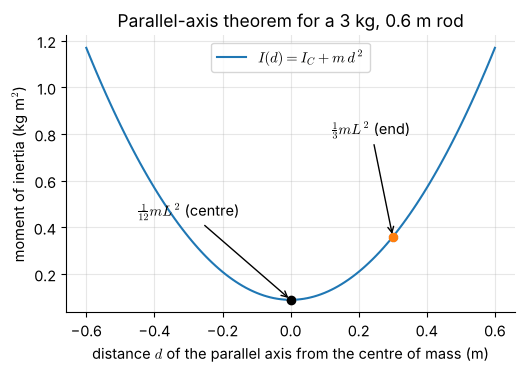

In [9]:
m_rod, L_rod = 3.0, 0.6
d = np.linspace(-0.6, 0.6, 121)
I_about = np.array([dyn.parallel_axis(dyn.inertia_rod(m_rod, L_rod, axis=0), m_rod, [0, di, 0])[2, 2] for di in d])   # axis z at distance d along y
print("I about centre :", dyn.inertia_rod(m_rod, L_rod, axis=0)[2, 2], " = m L^2/12 =", m_rod * L_rod**2 / 12)
print("I about the end:", dyn.parallel_axis(dyn.inertia_rod(m_rod, L_rod, axis=0), m_rod, [L_rod / 2, 0, 0])[2, 2], " = m L^2/3 =", m_rod * L_rod**2 / 3)

fig, ax = plt.subplots(figsize=(5.8, 3.6))
ax.plot(d, I_about, color="#1f77b4", label=r"$I(d)=I_C+m\,d^2$")
ax.plot(0, m_rod * L_rod**2 / 12, "o", color="k"); ax.annotate(r"$\frac{1}{12}mL^2$ (centre)", (0, m_rod * L_rod**2 / 12), (-0.45, 0.45), arrowprops=dict(arrowstyle="->"))
ax.plot(L_rod / 2, m_rod * L_rod**2 / 3, "o", color="#ff7f0e"); ax.annotate(r"$\frac{1}{3}mL^2$ (end)", (L_rod / 2, m_rod * L_rod**2 / 3), (0.12, 0.8), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("distance $d$ of the parallel axis from the centre of mass (m)"); ax.set_ylabel(r"moment of inertia (kg m$^2$)")
ax.set_title("Parallel-axis theorem for a 3 kg, 0.6 m rod"); ax.legend(); plt.show()

**Verification against MuJoCo.** Give MuJoCo a body made of two cubes with different masses at different places and ask it for the body's inertial parameters; it must
reproduce `combine_bodies`. (A cube of side $0.2$ has half-size $0.1$ in MuJoCo's convention.)

In [10]:
xml2 = """<mujoco><worldbody><body name="two">
  <geom type="box" size="0.1 0.1 0.1" pos="0.3 0 0"    mass="1"/>
  <geom type="box" size="0.1 0.1 0.1" pos="-0.1 0.2 0" mass="2"/>
</body></worldbody></mujoco>"""
mj2 = mujoco.MjModel.from_xml_string(xml2)
cube = lambda mass: dyn.inertia_box(mass, 0.2, 0.2, 0.2)
m_c, com_c, I_c = dyn.combine_bodies([(1.0, [0.3, 0, 0], cube(1.0)), (2.0, [-0.1, 0.2, 0], cube(2.0))])
b = mj2.body("two").id
print("mass          :", m_c, mj2.body_mass[b])
print("centre of mass:", com_c.round(5), mj2.body_ipos[b].round(5))
print("tensor about C: max difference", np.abs(mujoco_tensor(mj2, "two") - I_c).max())
assert np.allclose(mujoco_tensor(mj2, "two"), I_c, atol=1e-12) and np.allclose(com_c, mj2.body_ipos[b])

mass          : 3.0 3.0
centre of mass: [0.0333 0.1333 0.    ] [0.0333 0.1333 0.    ]
tensor about C: max difference 5.551115123125783e-17


## 7. Which matrices can be inertia tensors?

Not every symmetric matrix is the inertia tensor of a real body, and a mistyped entry in a robot description (a common source of bugs in simulators) can silently produce an
unphysical model. Two conditions characterise the physical ones.

1. **Positive definiteness.** $\boldsymbol\omega^{\mathsf T}I\boldsymbol\omega=\int|\boldsymbol\omega\times\mathbf r|^2dm\ge0$, with equality only for $\boldsymbol\omega$ along a line on which the whole mass lies (then the body is a thin rod about its own axis). Hence all principal moments are $\ge 0$.
2. **The triangle inequality.** $I_2+I_3-I_1=2\int x_1^2\,dm\ge0$ in the principal frame, so *every principal moment is at most the sum of the other two*:
$I_1\le I_2+I_3$, $I_2\le I_1+I_3$, $I_3\le I_1+I_2$.

Given $m$ and the principal moments, the **equivalent box** has full side lengths $a_1^2=\tfrac6m(I_2+I_3-I_1)$ and cyclically; MuJoCo draws it when asked to display inertia (Section 8). It exists exactly when the triangle inequality holds.

In [11]:
tests = {
    "uniform box 2 kg (0.6, 0.4, 0.2)": dyn.inertia_box(2.0, 0.6, 0.4, 0.2),
    "diag(1, 1, 3): violates I3 <= I1+I2": np.diag([1.0, 1.0, 3.0]),
    "diag(1, 2, -0.5): not positive": np.diag([1.0, 2.0, -0.5]),
    "product of inertia too large: not positive": np.array([[1.0, -1.2, 0], [-1.2, 1.0, 0], [0, 0, 1.0]]),
}
for name, I in tests.items():
    print(f"{name:45s} physical: {dyn.is_physical_inertia(I)}   eigenvalues {np.linalg.eigvalsh(I).round(3)}")
lam_box = np.diag(dyn.inertia_box(2.0, 0.6, 0.4, 0.2))
print("equivalent box recovered from the principal moments:", dyn.box_from_inertia(2.0, lam_box).round(6), "(true sides 0.6, 0.4, 0.2)")

uniform box 2 kg (0.6, 0.4, 0.2)              physical: True   eigenvalues [0.033 0.067 0.087]
diag(1, 1, 3): violates I3 <= I1+I2           physical: False   eigenvalues [1. 1. 3.]
diag(1, 2, -0.5): not positive                physical: False   eigenvalues [-0.5  1.   2. ]
product of inertia too large: not positive    physical: False   eigenvalues [-0.2  1.   2.2]
equivalent box recovered from the principal moments: [0.6 0.4 0.2] (true sides 0.6, 0.4, 0.2)


## 8. Inertia of real robots in MuJoCo

Every link of a MuJoCo model carries a mass `body_mass`, the position of its centre of mass `body_ipos` in the link frame, and its inertia in diagonal form
`body_inertia` together with the orientation `body_iquat` of the principal axes relative to the link frame — exactly the data of Craig's ${}^{C_i}I_i$, $m_i$ and ${}^{i}P_{C_i}$ for each link.
`dyn.chain_from_mujoco` collects them into a `SerialChain`; for the Panda it also merges the fixed hand and the two finger bodies into link 7 with the parallel-axis theorem, so that
its seven links are a faithful model of the arm.

The table below lists the **UR5e**: mass, centre of mass, principal moments, and the moment of inertia of each link about **its own joint axis** $\hat{\mathbf a}$, i.e. $\hat{\mathbf a}^{\mathsf T}\,{}^{o}I\,\hat{\mathbf a}$
with ${}^{o}I$ the tensor about the link-frame origin on the joint axis (parallel-axis theorem). The **Dynamixel 2R** and the **Franka Panda** are loaded in the same way.

In [12]:
from rgkit import robots
display(Markdown(robots.describe("ur5e")))
ur_model, ur_data = robots.load_robot("ur5e", scene="bare")
ur = dyn.chain_from_mujoco(ur_model, "wrist_3_link")
rows = []
for L in ur.links:
    lam_l, _ = dyn.principal_axes(L.I_com)
    rows.append(f"| `{L.name}` | {L.m:.3f} | {np.array2string(L.com, precision=3, suppress_small=True)} | "
                f"{np.array2string(lam_l, precision=5, suppress_small=True)} | {L.axis @ L.I_o @ L.axis:.5f} |")
display(Markdown("| link | mass (kg) | centre of mass in link frame (m) | principal moments (kg m²) | about joint axis (kg m²) |\n|:--|--:|:--|:--|--:|\n" + "\n".join(rows)))
print(f"total mass of the moving links: {sum(L.m for L in ur.links):.3f} kg  (model total including the fixed base: {ur_model.body_mass.sum():.3f} kg)")
for name, tip in [("2r", "second_segment"), ("panda", "hand")]:
    mdl, _ = robots.load_robot(name, scene="bare")
    ch = dyn.chain_from_mujoco(mdl, tip)
    print(f"{name:6s}: {ch.n} links, masses {[round(L.m, 3) for L in ch.links]} kg")

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)

| link | mass (kg) | centre of mass in link frame (m) | principal moments (kg m²) | about joint axis (kg m²) |
|:--|--:|:--|:--|--:|
| `shoulder_link` | 3.700 | [0. 0. 0.] | [0.00666 0.01027 0.01027] | 0.00666 |
| `upper_arm_link` | 8.393 | [0.    0.    0.212] | [0.01511 0.13389 0.13389] | 0.51288 |
| `forearm_link` | 2.275 | [0.    0.    0.196] | [0.00409 0.03118 0.03118] | 0.11858 |
| `wrist_1_link` | 1.219 | [0.    0.127 0.   ] | [0.00219 0.00256 0.00256] | 0.00256 |
| `wrist_2_link` | 1.219 | [0.  0.  0.1] | [0.00219 0.00256 0.00256] | 0.00219 |
| `wrist_3_link` | 0.189 | [0.    0.077 0.   ] | [0.0001  0.0001  0.00013] | 0.00013 |

total mass of the moving links: 16.995 kg  (model total including the fixed base: 20.995 kg)
2r    : 2 links, masses [0.287, 1.116] kg


panda : 7 links, masses [4.971, 0.647, 3.229, 3.588, 1.226, 1.667, 1.496] kg


The model's inertia can be *seen*: MuJoCo's `mjVIS_INERTIA` option draws, for every body, the equivalent box of Section 7 at its centre of mass. The left image is the usual
picture of the arm; on the right only the equivalent boxes are drawn. The boxes of the heavy upper-arm and forearm links are long and thin along the link, which is consistent with a small principal moment about the link's own axis (compare the table).

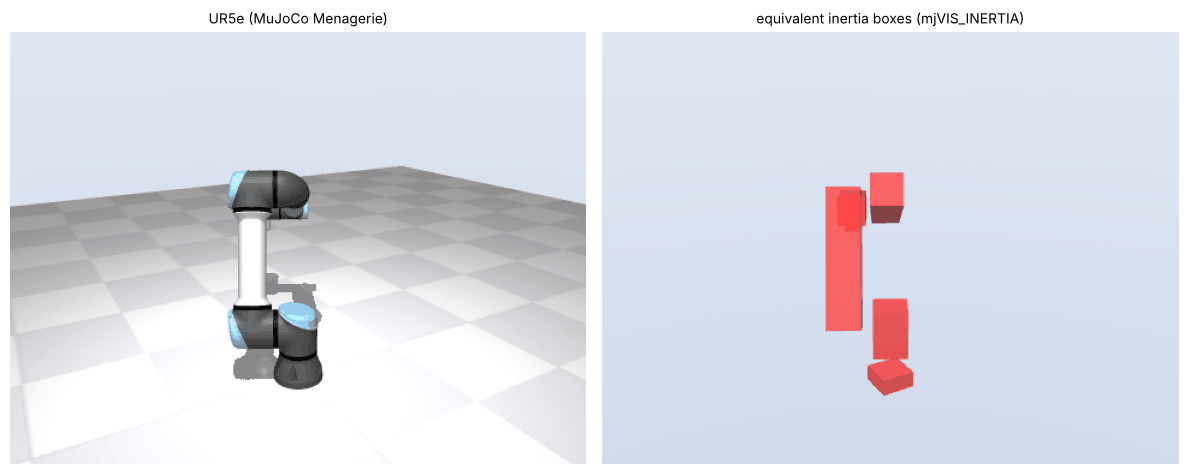

In [13]:
from rgkit import mujoco_utils as mju
model, data = robots.load_robot("ur5e")                    # the light scene with floor
data.qpos[:] = [-0.5, -1.2, 1.6, -1.9, -1.57, 0.0]; mujoco.mj_forward(model, data)
cam = dict(azimuth=150, elevation=-18, distance=1.5, lookat=(0, 0, 0.42))
opt = mujoco.MjvOption(); opt.flags[mujoco.mjtVisFlag.mjVIS_INERTIA] = True
for g in (0, 1, 2):
    opt.geomgroup[g] = 0                                   # hide the visual meshes, keep the equivalent inertia boxes
filmstrip([mju.render(model, data, camera=cam), mju.render(model, data, camera=cam, scene_option=opt)],
          ["UR5e (MuJoCo Menagerie)", "equivalent inertia boxes (mjVIS_INERTIA)"])

**From the tensor to the joint-space mass matrix.** The joint-space inertia $M(q)$ of the next notebooks has a direct meaning for the *last* joint of an arm: when only joint $n$ moves, only link $n$ moves, rotating about its own axis, so
$M_{nn}=\hat{\mathbf a}_n^{\mathsf T}\,{}^{o}I_n\,\hat{\mathbf a}_n$ (plus the **armature**, the reflected rotor inertia, which MuJoCo adds to the diagonal). More generally, $M_{11}$ is the moment of inertia of the **whole arm, frozen in its current pose, about the first joint axis**.
That statement uses every tool of this notebook: rotate each link's tensor into the base frame, move it to a common point with the parallel-axis theorem and add. The cell below does it for a random pose of the UR5e and for the Dynamixel 2R and compares with the mass matrix MuJoCo reports.

In [14]:
rng = np.random.default_rng(1)
q = rng.uniform(-1.5, 1.5, 6)
ur_data.qpos[:] = q; mujoco.mj_forward(ur_model, ur_data)
M_mj = dyn.mujoco_mass_matrix(ur_model, ur_data)
arm = ur_model.dof_armature
print("armature of the UR5e joints in the model (kg m^2):", arm)

# last joint: moment of the last link about its own axis
a6, Io6 = ur.links[5].axis, ur.links[5].I_o
print(f"M[5,5] - armature = {M_mj[5, 5] - arm[5]:.8f}    a^T I_o a = {a6 @ Io6 @ a6:.8f}")

# first joint: the whole arm, frozen at q, about the base z axis (the joint-1 axis)
parts = [(L.m, pc, R0i @ L.I_com @ R0i.T) for L, (_, _, R0i, pc) in zip(ur.links, dyn.link_jacobians(ur, q))]    # everything in the base frame
m_arm, com_arm, I_arm_C = dyn.combine_bodies(parts)
I_arm_O = dyn.parallel_axis(I_arm_C, m_arm, com_arm)                   # about the base origin, which lies on the joint-1 axis
print(f"M[0,0] - armature = {M_mj[0, 0] - arm[0]:.8f}    e_z^T I_arm,O e_z = {I_arm_O[2, 2]:.8f}")
assert np.isclose(M_mj[5, 5] - arm[5], a6 @ Io6 @ a6, atol=1e-10) and np.isclose(M_mj[0, 0] - arm[0], I_arm_O[2, 2], atol=1e-10)

armature of the UR5e joints in the model (kg m^2): [0.1 0.1 0.1 0.1 0.1 0.1]
M[5,5] - armature = 0.00013213    a^T I_o a = 0.00013213
M[0,0] - armature = 0.92999197    e_z^T I_arm,O e_z = 0.92999197


Both numbers agree with the simulator to rounding error: the inertia of the entire UR5e about its vertical axis, obtained by composing seven tensors, equals the first diagonal entry of $M(q)$ (less the armature).
This is the first *dynamical* result of the chapter: **the diagonal of the mass matrix is made of inertias of composite bodies about joint axes.**

## 9. Worked examples

Numbers in the text are generated by the same code that checks them in the cell below.

**Example 6.1.1 — point masses.** Masses of $2$, $1$ and $1$ kg sit at $(0.5,0,0)$, $(0,0.4,0)$ and $(-0.3,-0.2,0.1)$ m. Find the centre of mass and the inertia tensor (a) about the origin and (b) about the centre of mass.

*Solution.* $m=4$ kg and $\mathbf r_C=\frac14\sum m_k\mathbf r_k=(0.175,\ 0.05,\ 0.025)$ m. Summing $m_k\big(|\mathbf r_k|^2E-\mathbf r_k\mathbf r_k^{\mathsf T}\big)$ gives, about the origin,
$I_{xx}=0.21$, $I_{yy}=0.6$, $I_{zz}=0.79$ kg m$^2$ and $I_{xy}$-entry $-0.06$; about the centre of mass the diagonal is $(0.1975,\ 0.475,\ 0.6575)$ and the $(1,2)$ entry is $-0.025$.
Part (b) follows from part (a) by the inverse parallel-axis theorem, $I_C=I_O-m(\mathbf r_C^{\mathsf T}\mathbf r_C E-\mathbf r_C\mathbf r_C^{\mathsf T})$.

In [15]:
ms = np.array([2.0, 1.0, 1.0]); pts = np.array([[0.5, 0, 0], [0, 0.4, 0], [-0.3, -0.2, 0.1]])
rC = ms @ pts / ms.sum()
I_O = dyn.inertia_point_masses(ms, pts)
I_C = dyn.inertia_point_masses(ms, pts, about=rC)
assert np.allclose(rC, [0.175, 0.05, 0.025], atol=1e-4)
assert np.allclose(I_O, [[0.21, -0.06, 0.03], [-0.06, 0.6, 0.02], [0.03, 0.02, 0.79]], atol=1e-4)
assert np.allclose(I_C, [[0.1975, -0.025, 0.0475], [-0.025, 0.475, 0.025], [0.0475, 0.025, 0.6575]], atol=1e-4)
assert np.allclose(I_C, dyn.parallel_axis_inverse(I_O, ms.sum(), rC))
print("r_C =", rC, "\nI about O =\n", I_O, "\nI about C =\n", I_C)

r_C = [0.175 0.05  0.025] 
I about O =
 [[ 0.21 -0.06  0.03]
 [-0.06  0.6   0.02]
 [ 0.03  0.02  0.79]] 
I about C =
 [[ 0.1975 -0.025   0.0475]
 [-0.025   0.475   0.025 ]
 [ 0.0475  0.025   0.6575]]


**Example 6.1.2 — a rod hinged at its end.** A uniform rod of mass $3$ kg and length $0.6$ m is hinged at one end. Find its moment of inertia about the hinge axis (perpendicular to the rod).

*Solution.* About the centre, $I_C=\frac1{12}mL^2=0.09$ kg m$^2$; the hinge is $d=L/2=0.3$ m from the centre, so $I=I_C+md^2=0.36$ kg m$^2$ $=\frac13mL^2$, four times the central value.

In [16]:
m_r, L_r = 3.0, 0.6
I_end = dyn.parallel_axis(dyn.inertia_rod(m_r, L_r, axis=0), m_r, [L_r / 2, 0, 0])
assert np.isclose(I_end[2, 2], m_r * L_r**2 / 3) and np.isclose(I_end[2, 2], 0.3600, atol=1e-4)
print("I about the hinge:", I_end[2, 2], "kg m^2; ratio to central value:", I_end[2, 2] / (m_r * L_r**2 / 12))

I about the hinge: 0.36 kg m^2; ratio to central value: 3.9999999999999996


**Example 6.1.3 — the L-bracket.** Bar A ($2$ kg, $0.4\times0.1\times0.1$ m) lies along $x$ with one corner at the origin; bar B ($1.5$ kg, $0.1\times0.3\times0.1$ m) continues along $y$ from the end of the short side (Section 4).
Find the centre of mass, the tensor about it and the principal moments.

*Solution.* The first moments give $\mathbf r_C=(0.1357,\ 0.1357,\ 0.05)$ m with $m=3.5$ kg. Moving the two box tensors to $\mathbf r_C$ and adding gives
$I_{xx}=0.05012$, $I_{yy}=0.05012$, $I_{zz}=0.0944$ kg m$^2$ and $-I_{xy}=0.02571$; the principal moments are $0.0244$, $0.07583$ and $0.0944$ kg m$^2$, with the smallest about the
diagonal direction $(1,1,0)/\sqrt2$ — the long diagonal of the L. Because the bars are 0.1 m thick, $I_3$ is slightly smaller than $I_1+I_2$ (a perfectly flat lamina would give equality).

In [17]:
m_L, com_L, I_L = dyn.combine_bodies([(2.0, [0.20, 0.05, 0.05], dyn.inertia_box(2.0, 0.4, 0.1, 0.1)),
                                       (1.5, [0.05, 0.25, 0.05], dyn.inertia_box(1.5, 0.1, 0.3, 0.1))])
lam_L, V_L = dyn.principal_axes(I_L)
assert np.isclose(m_L, 3.5) and np.allclose(com_L, [0.1357, 0.1357, 0.05], atol=1e-4)
assert np.allclose(I_L, [[0.0501, 0.0257, 0.0], [0.0257, 0.0501, 0.0], [0.0, 0.0, 0.0944]], atol=1e-4)
assert np.allclose(lam_L, [0.0244, 0.0758, 0.0944], atol=1e-4)
assert np.allclose(abs(V_L[:2, 0]), np.sqrt(0.5))                      # smallest moment: the diagonal (1, 1, 0)/sqrt 2
# the same composite through the point-mass definition (fine grid of 20 000 equal masses per bar)
rng = np.random.default_rng(0)
pa = rng.uniform([0, 0, 0], [0.4, 0.1, 0.1], (20000, 3)); pb = rng.uniform([0, 0.1, 0], [0.1, 0.4, 0.1], (20000, 3))
I_mc = dyn.inertia_point_masses(np.r_[np.full(20000, 2.0 / 20000), np.full(20000, 1.5 / 20000)], np.r_[pa, pb], about=com_L)
print("Monte-Carlo estimate agrees to 2%:", np.allclose(I_mc, I_L, rtol=0.03, atol=2e-3))

Monte-Carlo estimate agrees to 2%: True


**Example 6.1.4 — a rotated box.** A box of mass $2$ kg and sides $0.4\times0.2\times0.1$ m has $I=\mathrm{diag}(0.008333,\ 0.02833,\ 0.03333)$ in its own axes. It is mounted so that its axes are rotated by $30^\circ$ about $\hat Z$ with respect to the frame of the link.
Find the tensor in the link axes.

*Solution.* ${}^{A}I=R_Z(30^\circ)\,{}^{B}I\,R_Z(30^\circ)^{\mathsf T}$, with $I_{xx}=I_1c^2+I_2s^2=0.01333$, $I_{yy}=I_1s^2+I_2c^2=0.02333$ and $-I_{xy}=(I_1-I_2)\,sc=-0.00866$ kg m$^2$
($I_1,I_2$ the first two diagonal entries, $c=\cos30^\circ$, $s=\sin30^\circ$), $I_{zz}=0.03333$ unchanged. The products of inertia are non-zero because the axes of the link are not the box's principal axes.

In [18]:
I_B = dyn.inertia_box(2.0, 0.4, 0.2, 0.1)
R = rotz(deg(30))
I_A = dyn.rotate_inertia(I_B, R)
c30, s30 = np.cos(deg(30)), np.sin(deg(30))
assert np.isclose(I_A[0, 0], I_B[0, 0] * c30**2 + I_B[1, 1] * s30**2) and np.isclose(I_A[1, 1], I_B[0, 0] * s30**2 + I_B[1, 1] * c30**2)
assert np.isclose(I_A[0, 1], (I_B[0, 0] - I_B[1, 1]) * s30 * c30) and np.isclose(I_A[2, 2], I_B[2, 2])
assert np.allclose(I_A, [[0.01333, -0.00866, 0.0], [-0.00866, 0.02333, 0.0], [0.0, 0.0, 0.03333]], atol=1e-5)
w_, V_ = dyn.principal_axes(I_A)
print("principal moments recovered:", w_.round(5), "= diag of the box:", np.sort(np.diag(I_B)).round(5))

principal moments recovered: [0.0083 0.0283 0.0333] = diag of the box: [0.0083 0.0283 0.0333]


**Example 6.1.5 — how much of the diagonal of $M$ is armature?** The UR5e model of the library gives every joint an armature (reflected rotor inertia) of $0.1$ kg m$^2$.
In the model's home keyframe, what fraction of each diagonal entry $M_{jj}$ of the joint-space mass matrix is armature?

*Solution.* Subtract the armature from MuJoCo's $M$ to obtain the rigid-link part, which Section 8 showed to be made of composite inertias, and divide.
The share is about one tenth for joint 1 (the whole arm turns about it) but rises towards $100\%$ for the wrist joints, whose links are light and small:
for the last joint the rigid part is only $1.3\times10^{-4}$ kg m$^2$, a thousand times smaller than the armature. For joints 4–6 the model's inertia is **dominated by the rotor**
— a first hint that joint-level effects (Notebook 6.5) cannot be ignored for a real arm.

In [19]:
mdl, dat = robots.load_robot("ur5e", scene="bare")            # loads the keyframe "home"
q_home = dat.qpos.copy()
mujoco.mj_forward(mdl, dat)
M_full = dyn.mujoco_mass_matrix(mdl, dat)
M_rigid = dyn.mass_matrix(ur, q_home)                          # the library's rigid-link mass matrix, without armature
share = mdl.dof_armature / np.diag(M_full)
print("keyframe q =", q_home.round(3))
print("rigid-link diagonal of M  :", np.diag(M_rigid).round(5))
print("armature share of M_jj    :", (100 * share).round(1), "%")
assert np.allclose(np.diag(M_full) - mdl.dof_armature, np.diag(M_rigid), atol=1e-10)
assert share[0] < 0.15 and share[5] > 0.99

keyframe q = [-1.571 -1.571  1.571 -1.571 -1.571  0.   ]
rigid-link diagonal of M  : [0.8808 2.0389 0.653  0.0204 0.0034 0.0001]
armature share of M_jj    : [10.2  4.7 13.3 83.  96.7 99.9] %


## 10. Summary

| Result | Formula |
|:--|:--|
| Centre of mass, first moment | $\mathbf r_C=\frac1m\sum m_k\mathbf r_k$, $\mathbf h=m\mathbf r_C$ |
| Inertia tensor | $I=\int\big[(\mathbf r^{\mathsf T}\mathbf r)E-\mathbf r\mathbf r^{\mathsf T}\big]dm$; moments $I_{xx}=\int(y^2+z^2)dm$; products $I_{xy}=\int xy\,dm$ enter with a minus sign |
| Angular momentum, energy | $\mathbf L=I\boldsymbol\omega$, $K=\frac12\boldsymbol\omega^{\mathsf T}I\boldsymbol\omega$ |
| Change of axes | ${}^{A}I={}^{A}_{B}R\,{}^{B}I\,{}^{A}_{B}R^{\mathsf T}$; principal moments and the trace are invariant |
| Principal axes | $I=V\,\mathrm{diag}(I_1,I_2,I_3)\,V^{\mathsf T}$; $\mathbf L\parallel\boldsymbol\omega$ only along a principal axis |
| Parallel axis | ${}^{P}I={}^{C}I+m\big[(\mathbf d^{\mathsf T}\mathbf d)E-\mathbf d\mathbf d^{\mathsf T}\big]$ |
| Composite body | combine the first moments, shift every tensor to the common centre, add |
| Physical tensor | symmetric, positive definite, each principal moment $\le$ the sum of the other two |
| Link inertia about its joint | $\hat{\mathbf a}^{\mathsf T}\,{}^{o}I\,\hat{\mathbf a}$; the diagonal of $M(q)$ is made of such composite inertias |

### Common mistakes

* Using the parallel-axis theorem **between two arbitrary points**: it holds only to or from the **centre of mass**. To move between two other points go through $C$ (or apply the theorem twice).
* Adding tensors that are **not about the same point or not in the same axes**. Always shift and rotate first.
* Forgetting the **sign convention** of the products of inertia (tensor entry $=-\int xy\,dm$) when copying data between a CAD tool, a textbook and a simulator.
* Confusing MuJoCo's **half-lengths** (`size`) with full side lengths, or reading `body_inertia` as the full tensor: it holds the *principal* moments, in the axes `body_iquat`.
* Assuming $\mathbf L\parallel\boldsymbol\omega$; this holds only along a principal axis (and is the origin of the gyroscopic term of the next notebook).
* Quoting the diagonal of $M(q)$ as the *link* inertia: it also contains the armature and, except for the last joint, the inertia of every distal link.

## Exercises

**6.1.1** Show that the moment of inertia of a thin uniform rod of length $L$ and mass $m$ about a perpendicular axis through its centre is $\frac1{12}mL^2$ (integrate), and use the parallel-axis theorem to find it about an axis through a point at one quarter of the length from an end.

<details><summary>Answer</summary>

$I_C=\int_{-L/2}^{L/2}\frac mL x^2dx=\frac mL\cdot\frac{2}{3}\big(\frac L2\big)^3=\frac1{12}mL^2$. The point at $L/4$ from an end is $d=L/4$ from the centre, so $I=\frac1{12}mL^2+m\frac{L^2}{16}=\frac7{48}mL^2$ ($=0.1458\,mL^2$).
</details>

**6.1.2** A uniform solid cylinder of mass $m$, radius $r$ and height $h$ rolls about a hinge on its curved surface parallel to the axis of the cylinder. Find the moment of inertia about the hinge, and the height $h$ for which the moment about a *transverse* axis through the centre equals the moment about the cylinder's own axis.

<details><summary>Answer</summary>

About the hinge: $\frac12mr^2+mr^2=\frac32mr^2$. Transverse central moment $\frac1{12}m(3r^2+h^2)$ equals $\frac12mr^2$ when $3r^2+h^2=6r^2$, i.e. $h=\sqrt3\,r$ (the cylinder is then "dynamically spherical" for its inertia tensor).
</details>

**6.1.3** The tensor of a body about its centre of mass is $\mathrm{diag}(0.02,\ 0.03,\ 0.04)$ kg m$^2$ and its mass is $2$ kg. What is the tensor about a point $\mathbf d=(0.1,\,0,\,0.2)$ m from the centre, in the same axes? What is the moment about the axis through that point parallel to $\hat Y$?

<details><summary>Answer</summary>

$I=I_C+m(\mathbf d^{\mathsf T}\mathbf dE-\mathbf d\mathbf d^{\mathsf T})$ with $\mathbf d^{\mathsf T}\mathbf d=0.05$: the matrix $m(\ldots)=\begin{bmatrix}0.08&0&-0.04\\0&0.10&0\\-0.04&0&0.02\end{bmatrix}$, so
$I=\begin{bmatrix}0.10&0&-0.04\\0&0.13&0\\-0.04&0&0.06\end{bmatrix}$ kg m$^2$. The moment about the $y$-parallel axis is $I_{yy}=0.13$ kg m$^2$ ($=0.03+2(0.1^2+0.2^2)$).
</details>

**6.1.4** Show that the three principal moments of any body satisfy the triangle inequality, and decide whether a body with $I=\mathrm{diag}(1,\,2,\,4)$ kg m$^2$ can exist.

<details><summary>Answer</summary>

In principal axes $I_2+I_3-I_1=\int[(x_1^2+x_3^2)+(x_1^2+x_2^2)-(x_2^2+x_3^2)]dm=2\int x_1^2dm\ge0$, and cyclically. For $(1,2,4)$: $4\le1+2$ is false, so no such body exists.
</details>

**6.1.5** (*Programming*) Write `inertia_of_mesh(vertices, faces, density)` for a closed triangle mesh using the signed-tetrahedron decomposition (each triangle with the origin forms a tetrahedron whose mass and tensor are known) — or approximate it by filling the mesh with random points — and test it on a unit cube.

<details><summary>Answer</summary>

A unit cube of density 1 has $m=1$ and $I_C=\frac16E$ ($=\frac1{12}(1+1)$ on the diagonal). The point-sampling version (uniform points inside the box, `dyn.inertia_point_masses`) reproduces this to about 1% with $10^5$ samples (verified below).
</details>

**6.1.6** (*MuJoCo*) For the Dynamixel 2R arm of the model library, compute $\hat{\mathbf a}^{\mathsf T}\,{}^{o}I_2\,\hat{\mathbf a}$ for the **second** link and compare with $M_{22}-$ armature from MuJoCo at an arbitrary configuration. Explain why $M_{11}$ cannot be obtained from one link only.

<details><summary>Answer</summary>

The second link is the last link, so $M_{22}=\hat{\mathbf a}_2^{\mathsf T}\,{}^{o}I_2\hat{\mathbf a}_2+$ armature $=0.03747+0.005=0.04247$ kg m$^2$ — the printed check below confirms it for any $q$. $M_{11}$ is the inertia of link 1 plus that of link 2 **in its current pose** about axis 1, which depends on $q_2$.
</details>

**6.1.7** Principal axes of a tensor with products of inertia: find the principal moments and axes of $I=\begin{bmatrix}3&-1&0\\-1&3&0\\0&0&5\end{bmatrix}$ kg m$^2$, and state whether the body is a planar lamina.

<details><summary>Answer</summary>

Eigenvalues $2,\,4,\,5$ with axes $(1,1,0)/\sqrt2$, $(1,-1,0)/\sqrt2$ and $(0,0,1)$. Since $5\ne2+4$ it is not a thin lamina in the $xy$ plane (a lamina would satisfy $I_3=I_1+I_2$); the triangle inequality holds ($5\le6$).
</details>

In [20]:
# Verification of the exercise answers
m_, L_ = 1.7, 0.9
assert np.isclose(dyn.parallel_axis(dyn.inertia_rod(m_, L_, axis=0), m_, [0, L_ / 4, 0])[2, 2], 7 / 48 * m_ * L_**2)          # 6.1.1
mc, rc, hc = 2.3, 0.15, np.sqrt(3) * 0.15                                                                                     # 6.1.2
Icyl = dyn.inertia_cylinder(mc, rc, hc)
assert np.isclose(Icyl[0, 0], Icyl[2, 2]) and np.isclose(dyn.parallel_axis(Icyl, mc, [rc, 0, 0])[2, 2], 1.5 * mc * rc**2)
Id = dyn.parallel_axis(np.diag([0.02, 0.03, 0.04]), 2.0, [0.1, 0, 0.2])                                                       # 6.1.3
assert np.allclose(Id, [[0.10, 0, -0.04], [0, 0.13, 0], [-0.04, 0, 0.06]])
assert not dyn.is_physical_inertia(np.diag([1.0, 2.0, 4.0]))                                                                    # 6.1.4
rng = np.random.default_rng(5)                                                                                                  # 6.1.5
pts = rng.uniform(-0.5, 0.5, (100000, 3))
I_cube = dyn.inertia_point_masses(np.full(len(pts), 1.0 / len(pts)), pts, about=[0, 0, 0])
assert np.allclose(I_cube, np.eye(3) / 6, rtol=0.02, atol=2e-3)
mdl2, dat2 = robots.load_robot("2r", scene="bare"); ch2 = dyn.chain_from_mujoco(mdl2, "second_segment")                         # 6.1.6
dat2.qpos[:] = [0.7, -1.1]; mujoco.mj_forward(mdl2, dat2)
Iaxis = ch2.links[1].axis @ ch2.links[1].I_o @ ch2.links[1].axis
print(f"6.1.6: a^T I a = {Iaxis:.5f},  M22 - armature = {dyn.mujoco_mass_matrix(mdl2, dat2)[1, 1] - mdl2.dof_armature[1]:.5f}")
assert np.isclose(Iaxis, dyn.mujoco_mass_matrix(mdl2, dat2)[1, 1] - mdl2.dof_armature[1], atol=1e-12) and np.isclose(Iaxis, 0.03747, atol=5e-6)
Ie = np.array([[3.0, -1, 0], [-1, 3, 0], [0, 0, 5]])                                                                            # 6.1.7
w7, V7 = dyn.principal_axes(Ie)
assert np.allclose(w7, [2, 4, 5]) and dyn.is_physical_inertia(Ie) and not np.isclose(w7[2], w7[0] + w7[1])
print("all exercise answers verified")

6.1.6: a^T I a = 0.03747,  M22 - armature = 0.03747
all exercise answers verified


## Further reading and lectures

* Craig, 3rd ed., Ch. 6, §6.3 (mass distribution); Lynch & Park, Ch. 8, §8.2; Siciliano et al., Ch. 7; Spong et al., the chapter on dynamics; for the tensor itself any textbook of rigid-body mechanics (for example Goldstein, Poole & Safko, *Classical Mechanics*, on the inertia tensor and principal axes).
* Lectures: [Prof. G. C. Nandi, *Mathematical Foundation of Robotics*, playlist 1, lessons 26–29 (dynamics)](https://youtube.com/playlist?list=PLFWlHcAOSQboRkC6DtxKIqXmErq0oc7S3); [Northwestern *Modern Robotics*, all videos](https://www.youtube.com/playlist?list=PLggLP4f-rq02vX0OQQ5vrCxbJrzamYDfx) (Chapter 8, dynamics of open chains); [Sapienza *Robotics 2*, Prof. A. De Luca](https://www.youtube.com/playlist?list=PLAQopGWlIcya6LnIF83QlJTqvpYmJXnDm).
* MuJoCo documentation: [computation of inertia from geoms](https://mujoco.readthedocs.io/en/stable/modeling.html#cinertia) and the `inertial` element in the [XML reference](https://mujoco.readthedocs.io/en/stable/XMLreference.html#body-inertial).

---

[Chapter contents](README.md)